# Архив: расширенное исследование FM v3 (только validation)

Для сдачи используется **temporal_metadata_v2**: [основной ноутбук](../../experiments.ipynb) и [README](../../README.md).

V3 не принята в основную версию: при росте validation NDCG@10 с 0.005808 до 0.008681
и Recall@10 с 0.009718 до 0.012059 покрытие каталога сократилось с 6.77% до 0.31%,
а Recall хвоста стал нулевым. Итоговые test-метрики и конфигурация v2 сохранены.
Новая FM не оценивалась на test. Решение оставить v2 принято после просмотра validation;
это не новый выбор по независимому holdout и не доказательство превосходства v2 по NDCG.

Ниже сохранены исходные выполненные секции 46–50 и их выводы.
Рабочий каталог при запуске — `homework_1/`.
Перерисовать только архив: `python scripts/execute_notebook.py --section fm_extended`.
Подробности и воспроизведение: [README архива](README.md).


In [1]:
from pathlib import Path
import os, sys, json, gzip, hashlib, math, random, textwrap
from collections import Counter
import importlib.metadata

_working = Path.cwd()
ROOT = next((p for p in [_working, _working/'homework_1', _working/'recsys'/'homework_1']
             if (p/'scripts/prepare_data.py').is_file()), None)
assert ROOT is not None, 'Запустите notebook из homework_1 или корня репозитория'
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
sys.path.insert(0, str(ROOT))
from scripts.prepare_data import deterministic_gzip, sha256

SEED = 42
K = 10
RELEVANCE_THRESHOLD = 4
VALIDATION_START = pd.Timestamp('2016-01-01', tz='UTC')
TEST_START = pd.Timestamp('2017-01-01', tz='UTC')
random.seed(SEED)
np.random.seed(SEED)
FIGURES = ROOT / 'reports/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
COLORS = ['#255F85', '#D87535', '#3B8C78', '#9274A6', '#6B7C8F']
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.prop_cycle': plt.cycler(color=COLORS), 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.18, 'axes.axisbelow': True,
    'savefig.dpi': 145,
})
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

def show_figure(name, fig):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def fmt(value):
    return f'{value:,}'.replace(',', ' ')

versions = {name: importlib.metadata.version(name) for name in
            ['numpy', 'scipy', 'pandas', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel']}
display(pd.Series(versions, name='Версия').to_frame())
from scripts.reporting import load_validation_report, load_final_report
_saved_protocol=json.loads((ROOT/'reports/evaluation_protocol.json').read_text())
validation_view={'stats':_saved_protocol['evaluation_diagnostics']['validation']}


,Версия
numpy,2.2.4
scipy,1.15.2
pandas,2.2.3
matplotlib,3.10.1
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


### 46. FM v3: аудит обучения и расширенный validation-поиск

Этот этап **не читает test-примеры, финальные веса и test-отчёты**, не объединяет train с validation,
не меняет `configs/final_models.json` и не переоценивает финальные таблицы v2.
Исходные временные метапризнаки сохранены: только train IDs/timestamps до 2016-01-01.

До запусков сохранены 16 вариантов в `configs/fm_extended_search.json`.
Первый этап: 16 моделей, контрольные эпохи 4/8/12. Лучшие четыре **разные конфигурации**
продолжают обучение с состояния 12-й эпохи до 20/36/60, включая AdaGrad accumulators и RNG.
Всего максимум 384 обученных эпохи и 60 validation-оценок. Число эпох — теперь часть подбора.
Выбор: максимум macro validation NDCG@10; ties — меньше эпох, затем trial ID.
Сетка и checkpoints не расширяются по промежуточным результатам.

Контроль `00_control_v2` обязан точно воспроизвести прежние веса и метрики на 12-й эпохе.
Это отделяет расширение исследования от возможной ошибки переписывания обучения.
Повторить в отдельной подготовленной копии: `python scripts/tune_fm_extended.py`.
Существующий поиск не перезаписывается. Для просмотра без данных:
`python scripts/execute_notebook.py --section fm_extended`.

Бюджет 384 эпохи относится к исправленному поиску. Отдельно сохранён неполный отладочный запуск;
он потребовал дополнительных вычислений и не участвует в выборе настроек.


In [3]:
from scripts.fm_extended_reporting import load_extended_report
extended=load_extended_report(ROOT)
ext_summary=extended['summary'];ext_search=extended['search'];ext_curves=extended['curves']
ext_config=ext_summary['configuration']
assert ext_summary['test_evaluated'] is False and ext_summary['train_validation_refit'] is False
assert not ext_summary['io_audit']['blocked_attempts']
assert ext_summary['training_audit']['control_weights_identical_to_v2']
display(pd.DataFrame(ext_config['trials']).set_index('trial'))
display(pd.Series(ext_summary['feature_diagnostics'],name='Прежние train-only метапризнаки').to_frame())
display(pd.Series(ext_summary['training_audit'],name='Аудит обучения и контроль').to_frame())
verification=json.loads((ROOT/'reports/fm_extended_validation/verification.json').read_text())
assert verification['test_evaluated'] is False and not verification['actual_forbidden_reads']
display(pd.Series(verification,name='Независимая проверка validation').to_frame())

,batch_size,init_scale,learning_rate,loss,n_factors,negative_seed,negatives_per_positive,regularization,resample,sampler,seed,shuffle_seed
trial,,,,,,,,,,,,
00_control_v2,1024,0.010,0.050,bce,16,137,2,0.000,False,uniform,42,43
01_resample_only,1024,0.010,0.050,bce,16,137,2,0.000,True,uniform,42,43
02_popularity_only,1024,0.010,0.050,bce,16,137,2,0.000,True,popularity,42,43
03_bce_small_step,256,0.010,0.010,bce,16,137,2,0.000,True,uniform,42,43
04_bce_32,256,0.050,0.010,bce,32,137,2,0.000,True,uniform,42,43
05_bce_four_negatives,512,0.010,0.030,bce,32,137,4,0.000,True,uniform,42,43
06_bce_64,512,0.010,0.010,bce,64,137,4,0.000,True,uniform,42,43
07_bce_eight_negatives,512,0.050,0.010,bce,32,137,8,0.000,True,uniform,42,43
08_bce_low_step,256,0.050,0.003,bce,32,137,4,0.000,True,uniform,42,43


,Прежние train-only метапризнаки
all_source_timestamps_before_query,True
features,59076
first_month_vocabulary,12
first_year_vocabulary,17
history_age_days_max,"5,923.000"
history_age_days_min,1.000
item_id_features,15578
max_active_item_features,6
max_source_timestamp,1451520000
metadata_assumption,timestamp is event availability; no historical...


,Аудит обучения и контроль
control_epoch12_metrics,{'catalog_coverage_at_10': 0.06772371292848889...
control_weights_identical_to_v2,True
fixed_sampling_examples,"{'examples': 849123, 'fingerprint': 'f8a61dd49..."
notes,[Full FM/BCE gradients previously pass finite ...
v2_item_offset_std,1.605
v2_median_personal_interaction_std,1.668
v2_probe_bce_initial,0.615


,Независимая проверка validation
verified_summary_sha256,1412b0eb1f57c4a5f9641aeaa4a312e6ef8bf931921ba8...
actual_forbidden_reads,[]
cohort_users,10207
independently_verified_rankings,10207
exact_full_fm_full_catalog_oracles,3
reloaded_checkpoint_reproduces_all_rankings,True
validation_evaluations,60
training_epoch_rows,384
historical_feature_availability_preserved,True
all_bpr_zero_positive_users_use_common_fallback,True


### 47. Функция потерь и negative sampling

BCE использует прежнюю формулу и градиент без изменений. Проверяются меньшие LR, batch size,
16/32/64 факторов, инициализация 0.01/0.05, 2/4/8 unseen negatives и resampling по эпохам.
Наблюдаемые ratings 1–3 остаются BCE negatives. Pairwise BPR для **той же полной FM**:

$$L=\frac1N\sum\log(1+\exp(-(s(u,i^+)-s(u,i^-))))+
\frac{\lambda}{4N}\sum_{\text{обе стороны пар}}\sum_j x_j^2(w_j^2+\|v_j\|^2).$$

Общий intercept сокращается. В BPR положительные train-пары сравниваются с unseen;
известные низкие оценки исключены из unseen sampler, но не добавляются отдельными BPR-парами.
Обучающий target отличается, а relevance/candidates/общий оценщик неизменны.

Uniform и popularity proposal имеют поддержку на всём fit-каталоге. Для popularity
$q(i)\propto(n_i^{positive}+1)^{0.75}$; rejection исключает **все** известные пользователю fit-товары.
Вероятность корректно условна на unseen. Это смещённый обучающий proposal без importance correction,
а не оценка вероятности покупки. Sampling с возвращением; будущие положительные пары не исключаются.
Resampling использует seed `137 + (epoch−1)`. Замороженный sampling допустим, но повторяет одну экспозицию.

Finite differences проверяют полный BPR-градиент, включая общие numeric/categorical features.
Отдельно проверены точное совпадение BCE с v2, условное распределение sampler и восстановление
состояния обучения. Probe BCE считается только по train; её нельзя напрямую сравнивать между BCE и BPR.

Пользователи BPR без положительных train-якорей не имеют обученного личного профиля:
их scores → NaN, затем применяется общий fit-only popularity fallback, без изменения когорты.
Неполный запуск до исправления этого случая исключён из выбора и сохранён в `archive/fm_extended_pre_fix/`.
Сетка и checkpoints исправленного повторного запуска не менялись.


,trial,loss,epoch,n_factors,learning_rate,regularization,batch_size,negatives_per_positive,sampler,resample,ndcg_at_10,recall_at_10
18,06_bce_64,bce,4,64,0.010000,0.000010,512,4,uniform,True,0.008681,0.012059
56,07_bce_eight_negatives,bce,60,32,0.010000,0.000100,512,8,uniform,True,0.007835,0.013158
57,03_bce_small_step,bce,20,16,0.010000,0.000010,256,2,uniform,True,0.007673,0.012078
12,04_bce_32,bce,4,32,0.010000,0.000010,256,2,uniform,True,0.007596,0.011954
32,10_bpr_32,bpr,12,32,0.030000,0.000010,512,1,uniform,True,0.007155,0.011541
45,15_bpr_four_negatives,bpr,4,32,0.010000,0.000010,512,4,uniform,True,0.007056,0.011026
35,11_bpr_64,bpr,12,64,0.030000,0.000010,512,1,uniform,True,0.006946,0.011156
36,12_bpr_regularized,bpr,4,32,0.010000,0.000100,256,1,uniform,True,0.006870,0.010913
26,08_bce_low_step,bce,12,32,0.003000,0.000010,256,4,uniform,True,0.006862,0.011854
1,00_control_v2,bce,8,16,0.050000,0.000010,1024,2,uniform,False,0.006835,0.011146


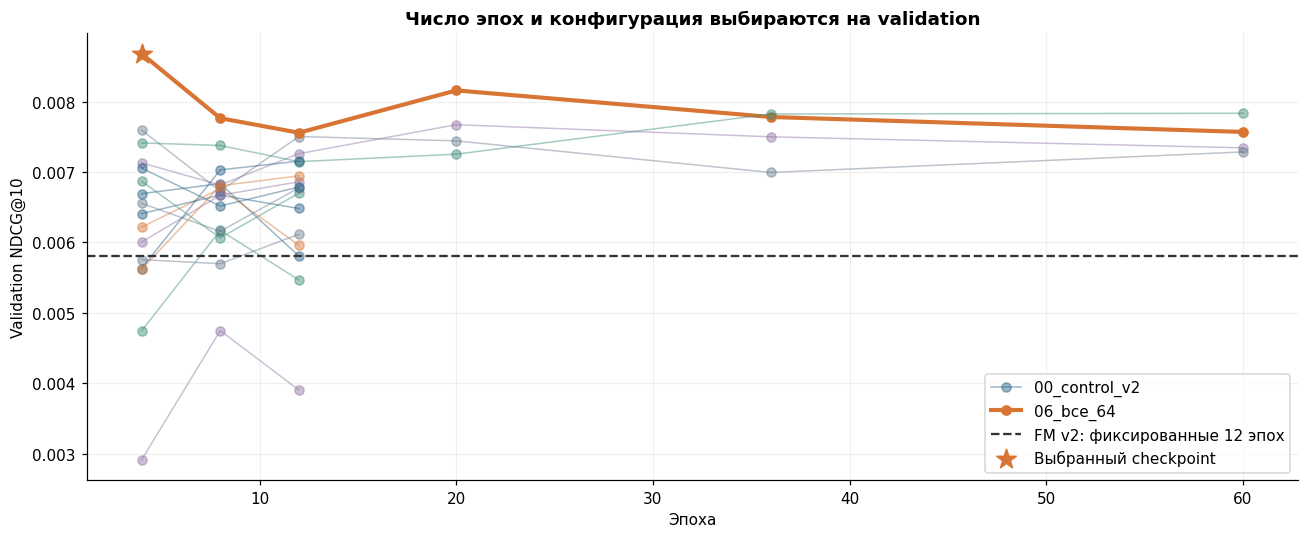

In [4]:
ext_best=ext_summary['best_checkpoint']
ext_best_by_trial=ext_search.sort_values(['ndcg_at_10','epoch','trial'],ascending=[False,True,True]).groupby('trial',sort=False).head(1)
with pd.option_context('display.float_format',lambda v:f'{v:.6f}'):
    display(ext_best_by_trial[['trial','loss','epoch','n_factors','learning_rate','regularization','batch_size','negatives_per_positive','sampler','resample','ndcg_at_10','recall_at_10']])
fig,ax=plt.subplots(figsize=(12,5))
for trial,g in ext_search.groupby('trial'):
    winner=trial==ext_best['trial'];g=g.sort_values('epoch')
    ax.plot(g.epoch,g.ndcg_at_10,marker='o',alpha=1 if winner else .45,lw=2.7 if winner else 1,
            label=trial if winner or trial=='00_control_v2' else None)
ext_old=float(extended['comparison'].set_index('model').loc['FM v2','ndcg_at_10'])
ax.axhline(ext_old,color='#333333',ls='--',label='FM v2: фиксированные 12 эпох')
ax.set(xlabel='Эпоха',ylabel='Validation NDCG@10',title='Число эпох и конфигурация выбираются на validation')
ax.scatter([ext_best['epoch']],[ext_best['ndcg_at_10']],marker='*',s=180,color=COLORS[1],zorder=10,label='Выбранный checkpoint')
ax.legend();show_figure('42_fm_extended_validation_learning',fig)

### 48. Повторяемость sampling и диагностика оптимизации

Три первых режима имеют одинаковые основные параметры. `00` против `01` изолирует resampling;
`01` против `02` — распределение предложения negatives. Сравниваем их на одной эпохе.
Количество разных hash отрицательных батчей показывает смену выборки, но не доказывает
покрытие всех unseen и не позволяет измерить долю ложных negatives без будущих данных.
Training losses показываются раздельно для BCE/BPR и не используются вместо validation-ранжирования.

Даже между BCE-вариантами разные ratios/samplers меняют распределение обучающих примеров.
По абсолютным train losses нельзя ранжировать эти режимы; сравниваем validation NDCG.

Для изолированного эффекта resampling на 12-й эпохе 95% парный bootstrap-интервал
разности NDCG включает ноль. Поэтому общий выигрыш нельзя объяснить одним пересэмплированием.
Дополнительные четыре validation-пересчёта после выбора служат только аудиту и контролируемой диагностике,
не добавляются к кандидатам и не меняют победителя из 60 плановых оценок.


,epochs,distinct_negative_batches,mean_duplicate_draw_fraction
trial,,,
00_control_v2,12,1,0.001
01_resample_only,12,12,0.001
02_popularity_only,12,12,0.002
03_bce_small_step,60,60,0.001
04_bce_32,60,60,0.001
05_bce_four_negatives,12,12,0.002
06_bce_64,60,60,0.002
07_bce_eight_negatives,60,60,0.004
08_bce_low_step,12,12,0.002


,trial,ndcg_at_10,recall_at_10
2,00_control_v2,0.006,0.010
5,01_resample_only,0.006,0.010
8,02_popularity_only,0.005,0.008


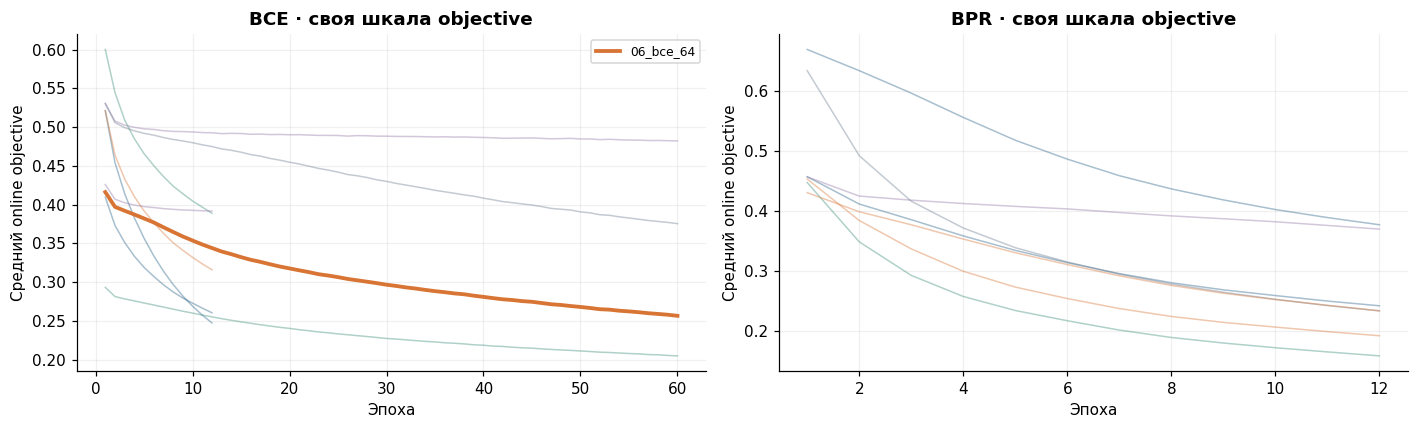

,comparison,metric,estimate_for,estimate,ci_low,ci_high
2,01_resample_only - 00_control_v2,ndcg_at_10,difference,0.000,-0.001,0.001
5,01_resample_only - 00_control_v2,recall_at_10,difference,0.001,-0.001,0.002
8,02_popularity_only - 01_resample_only,ndcg_at_10,difference,-0.000,-0.001,0.000
11,02_popularity_only - 01_resample_only,recall_at_10,difference,-0.002,-0.004,-0.000


In [5]:
ext_samples=extended['sampling'].copy()
ext_samples['duplicate_draw_fraction']=1-ext_samples.unique_unseen_pairs/ext_samples.sampled_draws
sampling_diagnostics=ext_samples.groupby('trial').agg(epochs=('epoch','count'),distinct_negative_batches=('negative_items_sha256','nunique'),mean_duplicate_draw_fraction=('duplicate_draw_fraction','mean'))
display(sampling_diagnostics)
display(ext_search[(ext_search.trial.isin(['00_control_v2','01_resample_only','02_popularity_only']))&(ext_search.epoch==12)][['trial','ndcg_at_10','recall_at_10']])
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,loss in zip(axes,['bce','bpr']):
    for trial,g in ext_curves[ext_curves.loss==loss].groupby('trial'):
        g=g.sort_values('epoch');winner=trial==ext_best['trial']
        ax.plot(g.epoch,g.online_objective,alpha=1 if winner else .4,lw=2.5 if winner else 1,label=trial if winner else None)
    ax.set(xlabel='Эпоха',ylabel='Средний online objective',title=loss.upper()+' · своя шкала objective')
    if ax.get_legend_handles_labels()[0]:ax.legend(fontsize=8)
show_figure('43_fm_extended_training_losses',fig)
control_intervals=pd.read_csv(ROOT/'reports/fm_extended_validation/sampling_control_bootstrap.csv')
display(control_intervals[control_intervals.estimate_for=='difference'])

### 49. Сравнение только на validation

Все строки используют 10 207 пользователей, полный train-каталог, прежние relevance, seen-mask и ties.
Четыре исходные модели и FM v2 переиспользуют проверенные персональные validation-метрики/выдачи.
Новая FM выбиралась среди большего числа настроек и checkpoints: сравнение имеет validation-оптимизм.
Парный bootstrap после HPO описательный, без поправки за множественные сравнения и seed-вариацию.
Test-метрик новой FM в этом разделе нет.


,model,catalog_coverage_at_10,evaluation_seconds,fallback_rate,ndcg_at_10,recall_at_10,users
0,Popularity,0.000963,1.224501,0.000000,0.005779,0.010252,10207
1,ItemKNN,0.738798,1.277437,0.051435,0.021111,0.032179,10207
2,iALS,0.143215,1.582736,0.050260,0.021893,0.034360,10207
3,EASE,0.497689,1.705730,0.051435,0.023372,0.035191,10207
4,FM v2,0.067724,1.404772,0.000000,0.005808,0.009718,10207
5,timeSVD++,0.338233,1.804576,0.000000,0.000616,0.000967,10207
6,FM extended,0.003081,1.513343,0.000000,0.008681,0.012059,10207


,baseline,metric,estimate_for,estimate,ci_low,ci_high
2,FM v2,ndcg_at_10,difference,0.002874,0.001558,0.004285
5,FM v2,recall_at_10,difference,0.002341,0.000266,0.004548
8,Popularity,ndcg_at_10,difference,0.002902,0.002099,0.003784
11,Popularity,recall_at_10,difference,0.001808,0.000674,0.002986
14,EASE,ndcg_at_10,difference,-0.014690,-0.016791,-0.012509
17,EASE,recall_at_10,difference,-0.023132,-0.026317,-0.019886


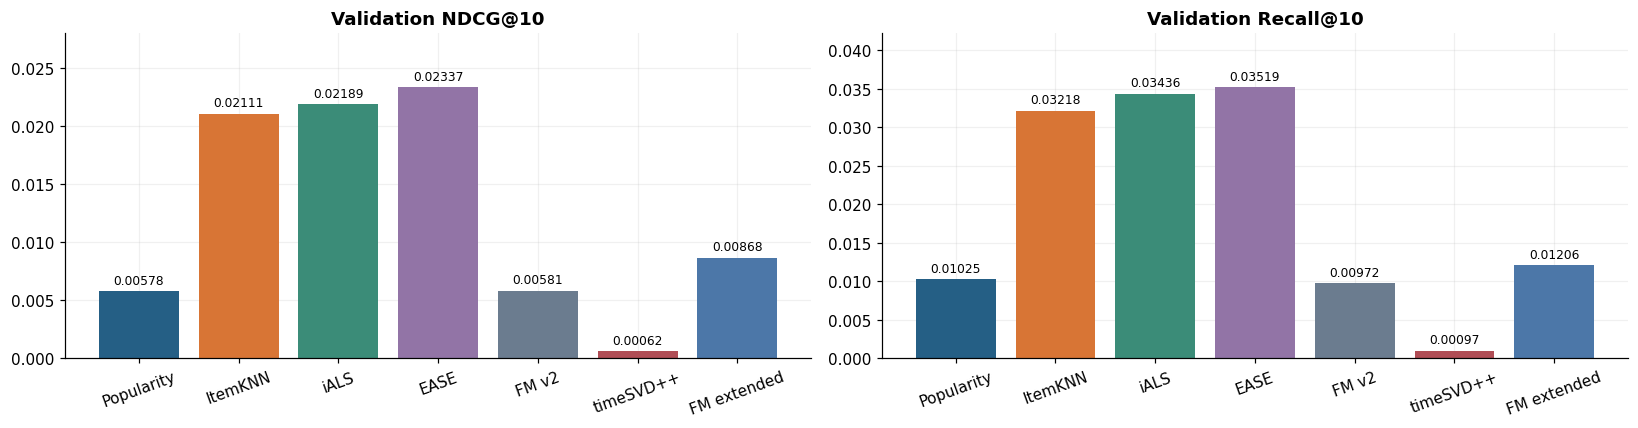

,model,history_slice,users,ndcg,recall,fallback_rate
0,Popularity,1-4,5943,0.007,0.011,0.000
1,Popularity,5-9,2766,0.005,0.009,0.000
2,Popularity,10+,1498,0.004,0.007,0.000
3,ItemKNN,1-4,5943,0.022,0.032,0.086
4,ItemKNN,5-9,2766,0.020,0.033,0.005
5,ItemKNN,10+,1498,0.021,0.030,0.000
6,iALS,1-4,5943,0.023,0.034,0.084
7,iALS,5-9,2766,0.021,0.037,0.005
8,iALS,10+,1498,0.020,0.030,0.000
9,EASE,1-4,5943,0.023,0.034,0.086


,model,item_slice,users,relevant_interactions,recall_at_10
0,Popularity,head_top_10_percent,5704,10248,0.024
1,Popularity,tail_other_90_percent,7765,15398,0.000
2,ItemKNN,head_top_10_percent,5704,10248,0.057
3,ItemKNN,tail_other_90_percent,7765,15398,0.014
4,iALS,head_top_10_percent,5704,10248,0.082
5,iALS,tail_other_90_percent,7765,15398,0.003
6,EASE,head_top_10_percent,5704,10248,0.069
7,EASE,tail_other_90_percent,7765,15398,0.012
8,FM v2,head_top_10_percent,5704,10248,0.023
9,FM v2,tail_other_90_percent,7765,15398,0.000


In [6]:
ext_comparison=extended['comparison'];ext_intervals=extended['intervals']
with pd.option_context('display.float_format',lambda v:f'{v:.6f}'):
    display(ext_comparison)
    display(ext_intervals[ext_intervals.estimate_for=='difference'])
fig,axes=plt.subplots(1,2,figsize=(15,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['Validation NDCG@10','Validation Recall@10']):
    ax.bar(ext_comparison.model,ext_comparison[metric],color=COLORS+['#B04D55','#4C77A8'])
    for i,value in enumerate(ext_comparison[metric]):ax.annotate(f'{value:.5f}',(i,value),xytext=(0,5),textcoords='offset points',ha='center',fontsize=8)
    ax.set(title=label,ylim=(0,ext_comparison[metric].max()*1.2));ax.tick_params(axis='x',rotation=20)
show_figure('44_fm_extended_validation_comparison',fig)
display(extended['history']);display(extended['popularity'])

### 50. Итоги расширенного подбора — test остаётся закрытым


In [7]:
ext_reference=ext_comparison.set_index('model').loc['FM v2']
ext_new_row=ext_comparison.set_index('model').loc['FM extended']
ext_gain=ext_best['ndcg_at_10']/ext_reference.ndcg_at_10-1
ext_ease=ext_comparison.set_index('model').loc['EASE']
ext_same_epoch=ext_search[(ext_search.trial=='00_control_v2')&(ext_search.epoch==12)].iloc[0]
display(pd.Series(ext_best,name='Выбранная конфигурация/checkpoint').to_frame())
display(Markdown(f"""
Выбран **{ext_best['trial']}**, loss **{ext_best['loss']}**, **{ext_best['epoch']} эпох**,
f={ext_best['n_factors']}, LR={ext_best['learning_rate']:g}, λ={ext_best['regularization']:g},
batch={ext_best['batch_size']}, negatives/positive={ext_best['negatives_per_positive']}, sampler={ext_best['sampler']}.
**Validation NDCG@10={ext_best['ndcg_at_10']:.6f}, Recall@10={ext_best['recall_at_10']:.6f}**.
Изменение NDCG относительно прежней FM v2 — **{ext_gain:+.1%}**;
EASE на той же validation имеет NDCG **{ext_ease.ndcg_at_10:.6f}**.
Coverage каталога упала с **{ext_reference.catalog_coverage_at_10:.2%}** до **{ext_new_row.catalog_coverage_at_10:.2%}**;
выдачи сильнее концентрируются на небольшом наборе товаров. Это компромисс, а не безусловный выигрыш.

Контроль на 12-й эпохе точно воспроизвёл v2, включая веса: явной ошибки BCE/AdaGrad не найдено.
Новый sampler исключает все наблюдавшиеся train-пары и имеет ненулевую поддержку всех остальных fit-товаров.
В BPR отсутствие положительных fit-якорей корректно обрабатывается общим popularity fallback.
Промежуточный дефект этого случая исправлен, отладочный запуск не участвует в выборе.
Результат зависит от сочетания objective, sampler, шага, ёмкости и выбранной эпохи;
глобальное улучшение нельзя целиком приписать одному изменению без отдельного контролируемого сравнения.
Отсев по ранним checkpoints может пропустить медленно обучающиеся режимы, особенно при сравнении objectives.
Сетка, promotion и checkpoints зафиксированы заранее; больший бюджет и checkpoint selection увеличивают оптимизм validation.

Историческая доступность признаков сохранена: metadata только из train IDs/timestamps до запроса.
**Test не читался и не оценивался в этом этапе, train+validation refit не выполнялся.**
Финальные таблицы в разделах 40–45 относятся к **v2**, а не к выбранной здесь FM.
Новые настройки хранятся отдельно в `reports/fm_extended_validation/summary.json`;
`configs/final_models.json` и исходные финальные отчёты сохранены.
"""))

,Выбранная конфигурация/checkpoint
additional_fit_seconds,24.880
batch_size,512
catalog_coverage_at_10,0.003
epoch,4
evaluation_seconds,1.513
fallback_rate,0.000
init_scale,0.010
learning_rate,0.010
loss,bce
n_factors,64



Выбран **06_bce_64**, loss **bce**, **4 эпох**,
f=64, LR=0.01, λ=1e-05,
batch=512, negatives/positive=4, sampler=uniform.
**Validation NDCG@10=0.008681, Recall@10=0.012059**.
Изменение NDCG относительно прежней FM v2 — **+49.5%**;
EASE на той же validation имеет NDCG **0.023372**.
Coverage каталога упала с **6.77%** до **0.31%**;
выдачи сильнее концентрируются на небольшом наборе товаров. Это компромисс, а не безусловный выигрыш.

Контроль на 12-й эпохе точно воспроизвёл v2, включая веса: явной ошибки BCE/AdaGrad не найдено.
Новый sampler исключает все наблюдавшиеся train-пары и имеет ненулевую поддержку всех остальных fit-товаров.
В BPR отсутствие положительных fit-якорей корректно обрабатывается общим popularity fallback.
Промежуточный дефект этого случая исправлен, отладочный запуск не участвует в выборе.
Результат зависит от сочетания objective, sampler, шага, ёмкости и выбранной эпохи;
глобальное улучшение нельзя целиком приписать одному изменению без отдельного контролируемого сравнения.
Отсев по ранним checkpoints может пропустить медленно обучающиеся режимы, особенно при сравнении objectives.
Сетка, promotion и checkpoints зафиксированы заранее; больший бюджет и checkpoint selection увеличивают оптимизм validation.

Историческая доступность признаков сохранена: metadata только из train IDs/timestamps до запроса.
**Test не читался и не оценивался в этом этапе, train+validation refit не выполнялся.**
Финальные таблицы в разделах 40–45 относятся к **v2**, а не к выбранной здесь FM.
Новые настройки хранятся отдельно в `reports/fm_extended_validation/summary.json`;
`configs/final_models.json` и исходные финальные отчёты сохранены.
